**Loading Dataset**

In [ ]:
import pandas as pd

df = pd.read_excel("Customer_Churn_Dataset.xlsx")

print(df.shape)
print(df.info())
print(df.head())

(7043, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

**Missing Values**

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


**TotalCharges is stored as an object instead of numeric**

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

**Remove CustomerId**

In [ ]:
df.drop("customerID", axis=1, inplace=True)

**Churn Distribution**

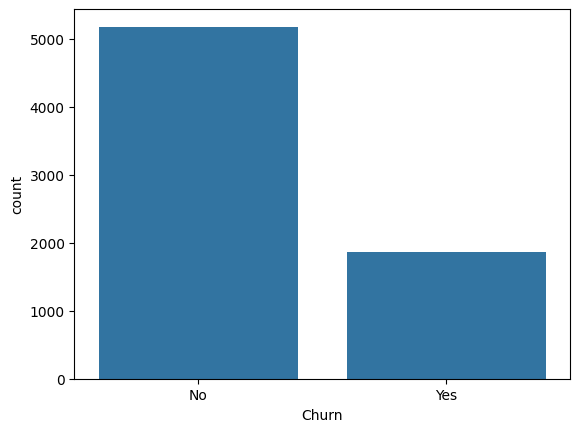

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Churn", data=df)
plt.show()

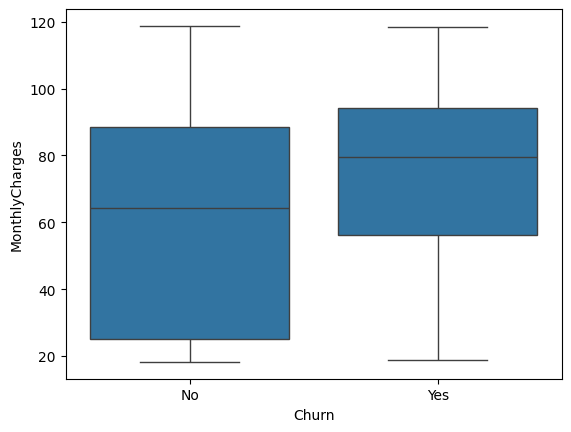

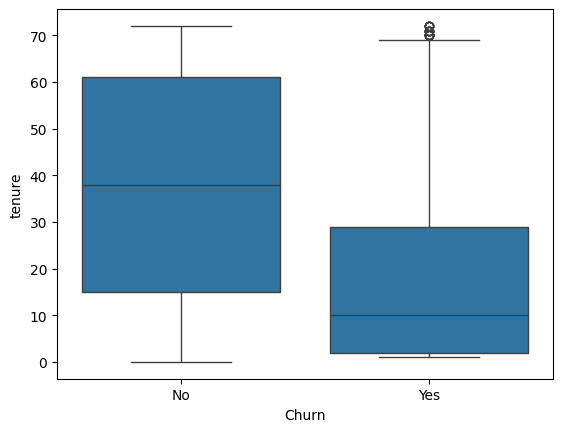

In [ ]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.show()

sns.boxplot(x="Churn", y="tenure", data=df)
plt.show()

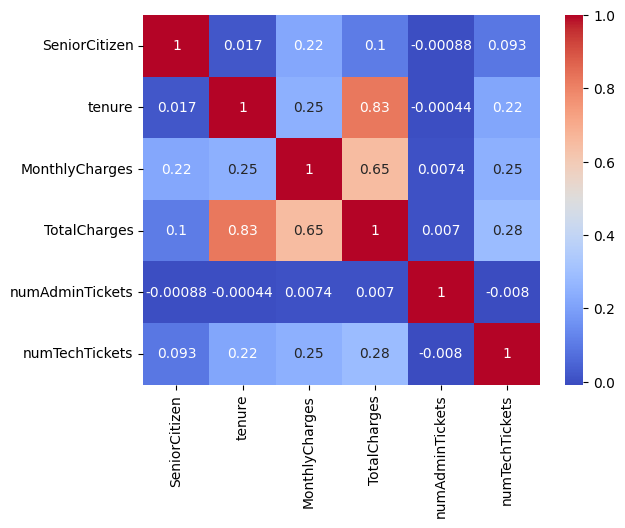

In [ ]:
sns.heatmap(df.select_dtypes(include="number").corr(),
            annot=True,
            cmap="coolwarm")
plt.show()

**Feature Engineering & Preprocessing**

Target Variable Conversion

In [ ]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

One-Hot Encoding

In [ ]:
df = pd.get_dummies(df, drop_first=True)

Split Features and Target

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Models**

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": lr,
    "Random Forest": rf
}

for name, model in models.items():
    pred = model.predict(X_test)
    print(name,
          accuracy_score(y_test, pred))

Logistic Regression 0.85805535841022
Random Forest 0.8530872959545777


Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    rf.predict(X_test)
))

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      1035
           1       0.76      0.66      0.70       374

    accuracy                           0.85      1409
   macro avg       0.82      0.79      0.80      1409
weighted avg       0.85      0.85      0.85      1409



Result

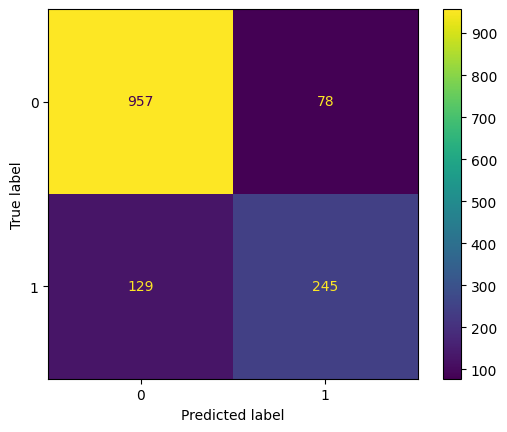

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf,
    X_test,
    y_test
)

plt.show()

ROC Curve

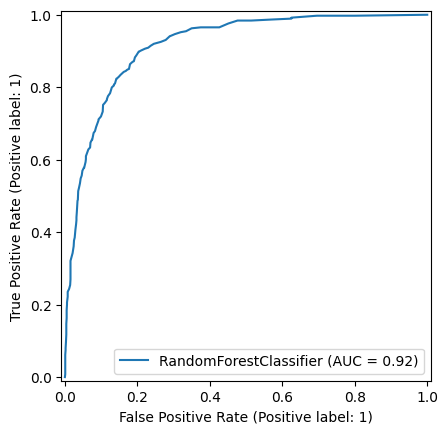

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    rf,
    X_test,
    y_test
)

plt.show()

Analysis:

Customers with month-to-month contracts churn more.

Customers with shorter tenure are more likely to leave.

Higher monthly charges increase churn probability.

Lack of tech support/security services is associated with churn.